In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("all_cpus.csv")
df.head()

,cpu_id,name,manufacturer,category,socket,cores,threads,base_clock_ghz,turbo_clock_ghz,performance_cores,...,l3_cache_mb,l2_cache_raw,l3_cache_raw,first_seen_quarter,first_seen_year,cpu_mark,single_thread_mark,sample_count,source_url,scraped_at_utc
0,7223,Intel Xeon 6973P-C,Intel,Server,FCLGA7529,1,2.0,NaN,NaN,NaN,...,480.0,1 x 2048 KB,480 MB,1.0,2026.0,4119,3396.0,2,https://www.cpubenchmark.net/cpu.php?cpu=Intel...,2026-09-13T20:19:40+00:00
1,5753,QTI SG8175P,Other,Mobile/Embedded,NaN,8,8.0,3.0,NaN,NaN,...,NaN,NaN,NaN,4.0,2023.0,7082,2534.0,5,https://www.cpubenchmark.net/cpu.php?cpu=QTI+S...,2026-09-13T20:19:41+00:00
2,6895,Mediatek MT9676,Other,Mobile/Embedded,NaN,4,4.0,1.7,NaN,NaN,...,NaN,NaN,NaN,3.0,2025.0,635,421.0,1,https://www.cpubenchmark.net/cpu.php?cpu=Media...,2026-09-13T20:19:43+00:00
3,3945,Samsung Exynos 7904,Samsung,Mobile/Embedded,NaN,8,8.0,1.8,NaN,NaN,...,NaN,NaN,NaN,1.0,2021.0,1861,755.0,360,https://www.cpubenchmark.net/cpu.php?cpu=Samsu...,2026-09-13T20:19:44+00:00
4,223,AMD Athlon XP 2000+,AMD,Desktop,Socket A,1,1.0,1.7,NaN,NaN,...,NaN,1 x 256 KB,NaN,1.0,2009.0,195,311.0,53,https://www.cpubenchmark.net/cpu.php?cpu=AMD+A...,2026-09-13T20:19:45+00:00


In [47]:
to_drop = [
    # Идентификаторы и технические данные
    "cpu_id",
    "source_url",
    "scraped_at_utc",
    "socket"

    # Дубли необработанных значений
    "l2_cache_raw",
    "l3_cache_raw",

    # Слишком много пропусков
    "performance_cores",
    "efficiency_cores",
    "efficiency_base_clock_ghz",
    "efficiency_turbo_clock_ghz",

    # Другой результат бенчмарка — потенциальная утечка
    "single_thread_mark",

    # Не характеристика мощности CPU
    "sample_count",

    # Дублируется с годом после преобразования
    "first_seen_quarter"
]

semi_null_features = []
df = df.drop(to_drop, axis=1)
print("features dropped")
for column in df.columns:
    fullness = 1 - sum(df[column].isna()) / len(df[column])
    print(f'{column}: {fullness}')
    if 0.4 <= fullness <= 0.8: semi_null_features.append(column)

features dropped
name: 1.0
manufacturer: 1.0
category: 0.928654775795966
socket: 0.6856142690448408
cores: 1.0
threads: 0.9563260543423904
base_clock_ghz: 0.9451575262543758
turbo_clock_ghz: 0.4739123187197867
tdp_w: 0.7099516586097683
l2_cache_mb: 0.6967827971328555
l3_cache_mb: 0.5004167361226871
first_seen_year: 0.9998333055509252
cpu_mark: 1.0


In [48]:
df.to_csv("cleaned.csv")

In [42]:
semi_null_features

['socket',
 'turbo_clock_ghz',
 'tdp_w',
 'l2_cache_mb',
 'l3_cache_mb',
 'l2_cache_raw',
 'l3_cache_raw']

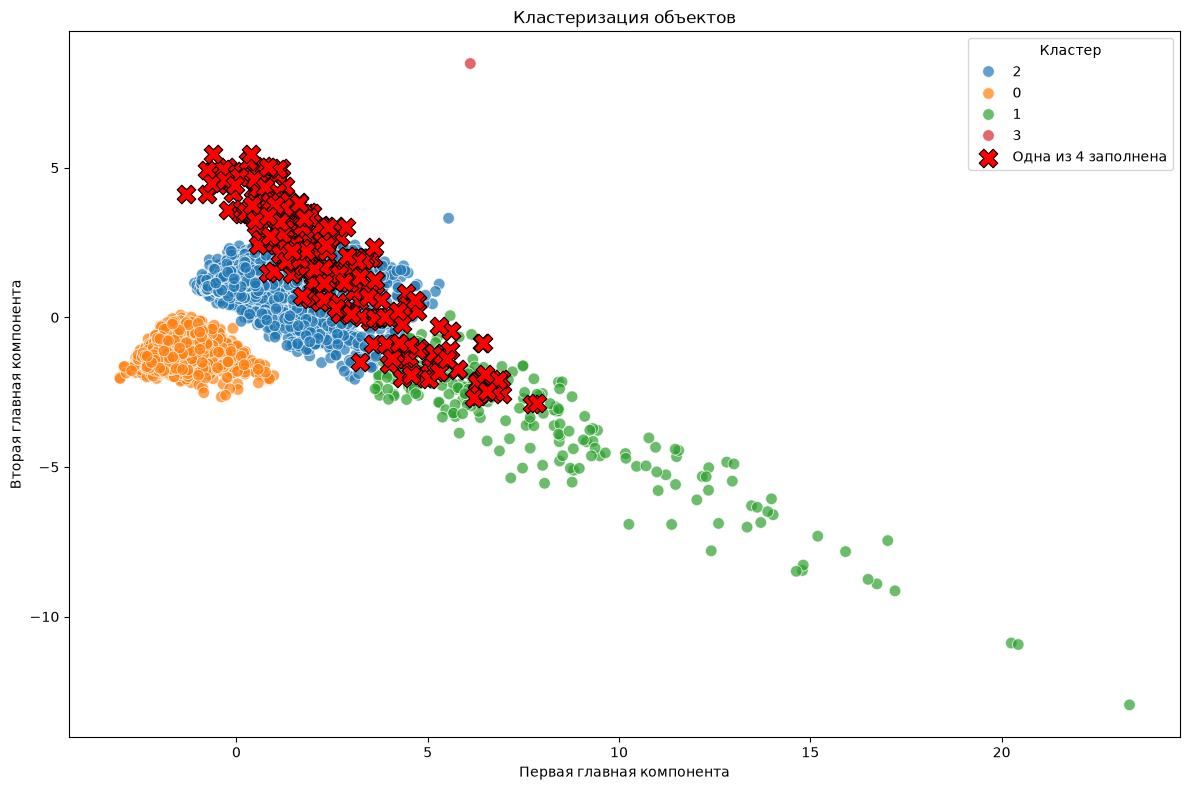

In [35]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


# Признаки, заполненность которых нужно выделить
required_features = [
    "performance_cores",
    "efficiency_cores",
    "efficiency_base_clock_ghz",
    "efficiency_turbo_clock_ghz"
]

# Маска объектов, у которых заполнены все четыре признака
highlight_mask = df[required_features].notna().any(axis=1)


# Берём все числовые признаки для кластеризации
numeric_columns = df.select_dtypes(include="number").columns

X = df[numeric_columns].copy()

# Заполняем пропуски медианными значениями
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)


# Стандартизируем признаки
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)


# Кластеризация
n_clusters = 4

kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)


# Сохраняем номера кластеров в исходном датафрейме
df["cluster"] = clusters


# Снижаем размерность до двух компонентов для визуализации
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)


# Датафрейм для построения графика
plot_df = pd.DataFrame(
    {
        "PC1": X_pca[:, 0],
        "PC2": X_pca[:, 1],
        "cluster": clusters.astype(str),
        "highlight": highlight_mask.to_numpy()
    },
    index=df.index
)


# Визуализация кластеров
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    s=70,
    alpha=0.7
)


# Выделяем красным объекты с заполненными четырьмя признаками
highlighted_objects = plot_df[plot_df["highlight"]]

sns.scatterplot(
    data=highlighted_objects,
    x="PC1",
    y="PC2",
    color="red",
    marker="X",
    s=180,
    edgecolor="black",
    linewidth=0.8,
    label="Одна из 4 заполнена"
)

plt.title("Кластеризация объектов")
plt.xlabel("Первая главная компонента")
plt.ylabel("Вторая главная компонента")
plt.legend(title="Кластер")
plt.tight_layout()
plt.show()

In [34]:
strange_cpus = df[df['performance_cores'].isna() == False]
for column in strange_cpus.columns:
    print(f'{column}: {1 - sum(strange_cpus[column].isna()) / len(strange_cpus[column])}')

cpu_id: 1.0
name: 1.0
manufacturer: 1.0
category: 0.9863013698630136
socket: 0.9657534246575342
cores: 1.0
threads: 1.0
base_clock_ghz: 0.9554794520547946
turbo_clock_ghz: 0.976027397260274
performance_cores: 1.0
efficiency_cores: 1.0
efficiency_base_clock_ghz: 0.8287671232876712
efficiency_turbo_clock_ghz: 0.9554794520547946
tdp_w: 0.976027397260274
l2_cache_mb: 0.9554794520547946
l3_cache_mb: 0.9554794520547946
l2_cache_raw: 0.9554794520547946
l3_cache_raw: 0.9554794520547946
first_seen_quarter: 1.0
first_seen_year: 1.0
cpu_mark: 1.0
single_thread_mark: 1.0
sample_count: 1.0
source_url: 1.0
scraped_at_utc: 1.0
cluster: 1.0


<Axes: xlabel='l2_cache_mb', ylabel='cpu_mark'>

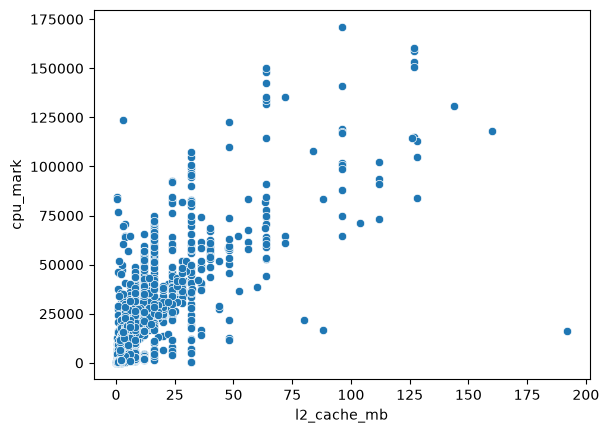

In [43]:
sns.scatterplot(data=df, x='l2_cache_mb', y='cpu_mark')